In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from banco import get_engine, executar

engine = get_engine()
pd.set_option("display.max_colwidth", 80)
pd.options.display.float_format = "{:,.2f}".format

def consulta(sql):
    return pd.read_sql(sql, engine)

def grafico_barras(df, rotulo, valor, titulo, eixo_x):
    d = df.sort_values(valor).copy()
    d[rotulo] = d[rotulo].astype(str).str.slice(0,45)
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(d) + 2))
    ax.barh(d[rotulo], d[valor].astype(float))
    ax.set_title(titulo)
    ax.set_xlabel(eixo_x)
    ax.ticklabel_format(axis="x", style="plain")
    plt.tight_layout()
    plt.show()

,nome_orgao_superior,qtd_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486,933,121.65"
1,Ministério da Defesa,61912,"156,070,304.49"
2,Ministério da Educação,65295,"111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49,697,710.16"
4,Ministério da Previdência Social,8190,"40,417,309.06"


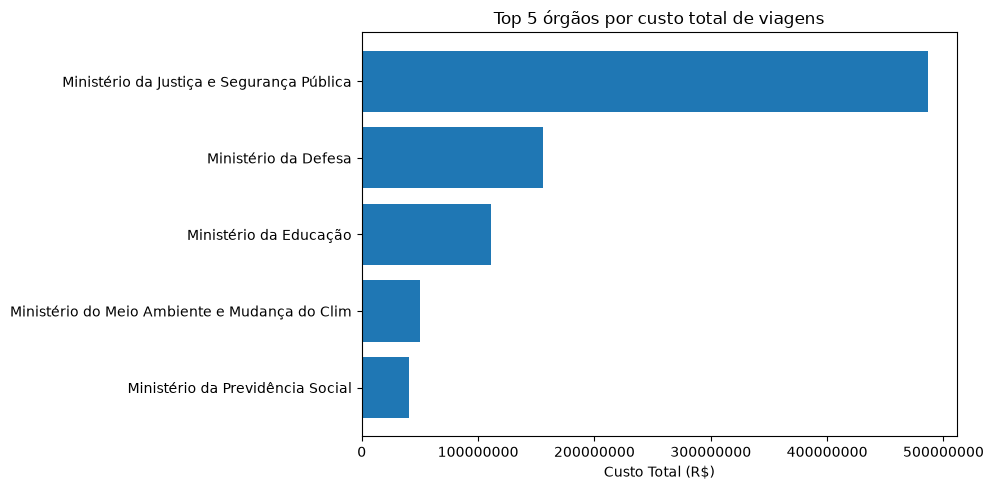

In [3]:
#Part 1 - Perguntas respondidas na Silver
# 1 - Quais os 5 órgãos com maior custo total?
SQL_Q1 = """
SELECT 
    nome_orgao_superior,
    count(*) as qtd_viagens,
    sum(valor_total) as custo_total
FROM 
silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5
"""
q1 = consulta(SQL_Q1)
display(q1)
grafico_barras(q1, "nome_orgao_superior", "custo_total",
               "Top 5 órgãos por custo total de viagens", "Custo Total (R$)")


,destinos,qtd_viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,"245,852.80"
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, ...",1,"216,729.36"
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasíl...",1,"207,220.14"


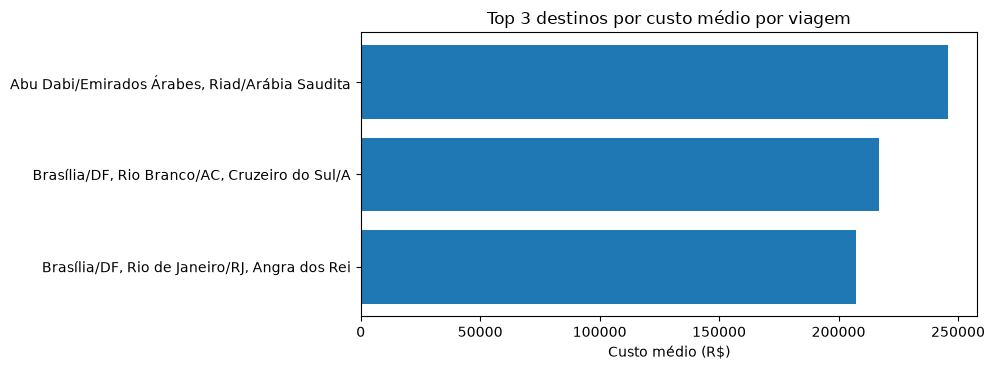

In [4]:
# 2 - Quais os 3 destinos com maior custo médio por viagem?
SQL_Q2 = """
SELECT 
    destinos,
    count(*) as qtd_viagens,
    avg(valor_total) as custo_medio
FROM
silver_viagem
where
destinos is not null
group by destinos
order by custo_medio desc
limit 3
"""
q2 = consulta(SQL_Q2)
display(q2)
grafico_barras(q2, "destinos", "custo_medio",
               "Top 3 destinos por custo médio por viagem", "Custo médio (R$)")

In [5]:
SQL_Q2B = """

SELECT 
    destinos,
    count(*) as qtd_viagens,
    avg(valor_total) as custo_medio
FROM
silver_viagem
where
destinos is not null
group by destinos
having count(*) >= 30
order by custo_medio desc
limit 3
"""


display(consulta(SQL_Q2B))

,destinos,qtd_viagens,custo_medio
0,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",91,"105,470.37"
1,"Brasília/DF, Brasília/DF, Brasília/DF",88,"100,317.26"
2,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",47,"97,736.69"


,id_viagem,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,379,"120,650.00"
2,0000000000020793492,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,370,"113,382.50"
3,0000000000020774569,Ministério da Educação,2025-02-26,2026-03-02,370,0.00
4,0000000000020592696,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,"159,044.90"
5,0000000000020685666,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,"124,312.50"
6,0000000000020589962,Ministério da Educação,2025-02-23,2026-02-23,366,0.00
7,0000000000020732132,Ministério da Educação,2025-03-31,2026-03-31,366,0.00
8,0000000000020557147,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,365,"216,729.36"
9,0000000000020649880,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,365,"207,220.14"


Resposta: viagem 0000000000020699856 - 384 dias, custo total R$ 0.00


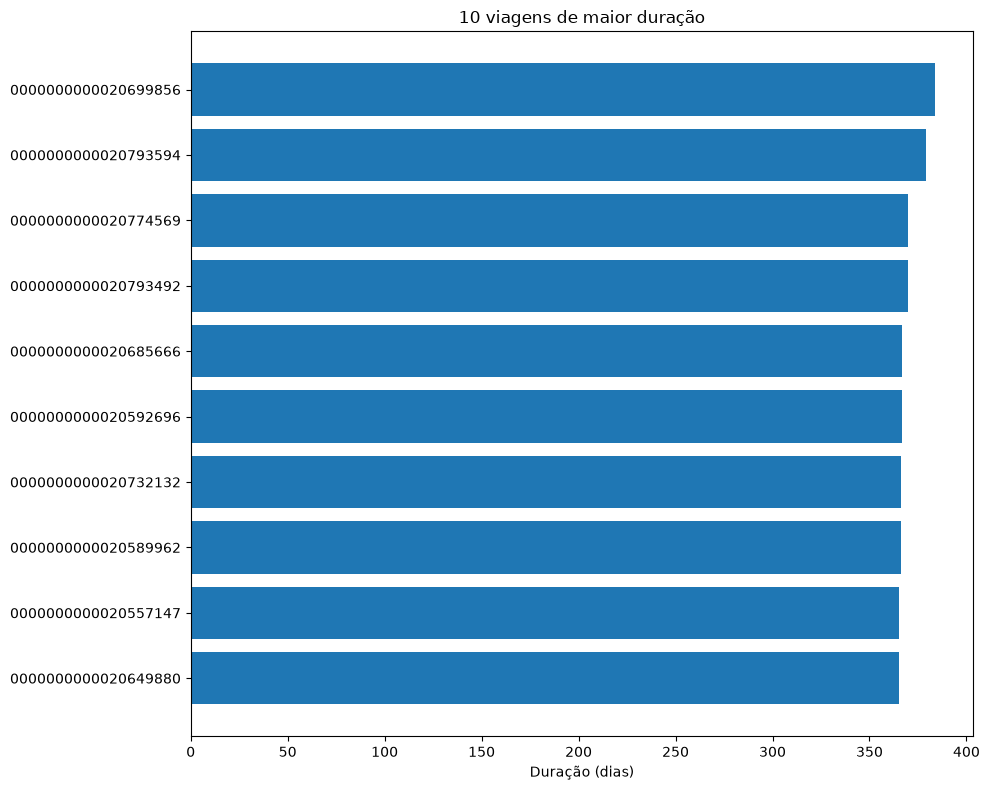

In [6]:
# 3 - Qual a viagem de maior duração e qual o seu custo total?
SQL_Q3 = """

SELECT 
    id_viagem, 
    nome_orgao_superior, 
    data_inicio, 
    data_fim,
    duracao_dias, 
    valor_total
FROM silver_viagem
where
duracao_dias is not null
order by duracao_dias desc, valor_total desc
limit 10
"""

q3 = consulta(SQL_Q3)
display(q3)
top = q3.iloc[0]
print(f"Resposta: viagem {top['id_viagem']} - {top['duracao_dias']} dias, "
      f"custo total R$ {top['valor_total']:,.2f}")
grafico_barras(q3, "id_viagem", "duracao_dias",
               "10 viagens de maior duração", "Duração (dias)")
